In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q transformers torchaudio librosa scikit-learn matplotlib seaborn pandas numpy tqdm

import torch
import torch.nn.functional as F
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from collections import Counter, defaultdict
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize
import json
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Mounted at /content/drive
Device: cuda


In [ ]:
CONFIG = {
    'RAVDESS_PATH': '/content/drive/MyDrive/Datasets/RAVDESS/AudioFiles',
    'MODEL_NAME': 'superb/wav2vec2-base-superb-er',
    'SAMPLE_RATE': 16000,
    'MAX_DURATION': 4,
    'TARGET_EMOTIONS': {
        '01': 'neutral',
        '03': 'happy',
        '05': 'angry',
        '04': 'sad'
    },
    'EMOTION_MAP': {
        'neutral': 'neu',
        'happy': 'hap',
        'angry': 'ang',
        'sad': 'sad'
    }
}

In [ ]:
from transformers import AutoModelForAudioClassification, AutoFeatureExtractor

feature_extractor = AutoFeatureExtractor.from_pretrained(CONFIG['MODEL_NAME'])
model = AutoModelForAudioClassification.from_pretrained(CONFIG['MODEL_NAME'])

model.to(device)
model.eval()

id2label = model.config.id2label
label2id = model.config.label2id

model_emotions = [id2label[i] for i in range(len(id2label))]
num_classes = len(model_emotions)

print("Model label order:")
for i in range(num_classes):
    print(i, "→", id2label[i])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

Model label order:
0 → neu
1 → hap
2 → ang
3 → sad


In [ ]:
class RAVDESSParser:
    @staticmethod
    def parse(filename):
        parts = Path(filename).stem.split('-')
        if len(parts) != 7:
            return None
        return {
            'emotion_code': parts[2],
            'actor_id': parts[6],
            'is_speech': parts[1] == '01',
            'is_audio_only': parts[0] == '03'
        }

def load_ravdess(path):
    samples = []
    audio_path = Path(path)

    for actor_folder in audio_path.iterdir():
        if not actor_folder.is_dir():
            continue

        for wav_file in actor_folder.glob("*.wav"):
            info = RAVDESSParser.parse(wav_file.name)
            if info is None:
                continue

            if (info['is_audio_only'] and
                info['is_speech'] and
                info['emotion_code'] in CONFIG['TARGET_EMOTIONS']):

                ravdess_emo = CONFIG['TARGET_EMOTIONS'][info['emotion_code']]
                model_emo = CONFIG['EMOTION_MAP'][ravdess_emo]

                samples.append({
                    'path': str(wav_file),
                    'model_emotion': model_emo
                })

    return samples

samples = load_ravdess(CONFIG['RAVDESS_PATH'])
print("Total samples:", len(samples))

Total samples: 672


In [ ]:
def preprocess_audio(file_path):
    waveform, sr = librosa.load(
        file_path,
        sr=CONFIG['SAMPLE_RATE'],
        mono=True
    )

    max_len = CONFIG['MAX_DURATION'] * CONFIG['SAMPLE_RATE']

    if len(waveform) > max_len:
        waveform = waveform[:max_len]
    else:
        waveform = np.pad(waveform, (0, max_len - len(waveform)))

    return waveform

In [ ]:
def run_inference(samples, batch_size=16):
    all_preds = []
    all_true = []
    all_probs = []

    for i in tqdm(range(0, len(samples), batch_size)):
        batch = samples[i:i+batch_size]

        waveforms = [preprocess_audio(s['path']) for s in batch]

        inputs = feature_extractor(
            waveforms,
            sampling_rate=CONFIG['SAMPLE_RATE'],
            return_tensors="pt",
            padding=True
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)
            preds = torch.argmax(probs, dim=-1)

        for idx, sample in enumerate(batch):
            pred_idx = preds[idx].item()
            true_idx = label2id[sample['model_emotion']]

            all_preds.append(pred_idx)
            all_true.append(true_idx)
            all_probs.append(probs[idx].cpu().numpy())

    return np.array(all_preds), np.array(all_true), np.array(all_probs)

y_pred, y_true, y_prob = run_inference(samples)

100%|██████████| 42/42 [03:57<00:00,  5.66s/it]


In [ ]:
accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average='macro'
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=model_emotions))

Accuracy: 0.4166666666666667
Precision: 0.5286456629370324
Recall: 0.45182291666666663
F1: 0.339356716759374

Classification Report:

              precision    recall  f1-score   support

         neu       0.33      0.70      0.45        96
         hap       0.31      0.14      0.19       192
         ang       0.48      0.92      0.63       192
         sad       1.00      0.05      0.09       192

    accuracy                           0.42       672
   macro avg       0.53      0.45      0.34       672
weighted avg       0.56      0.42      0.32       672



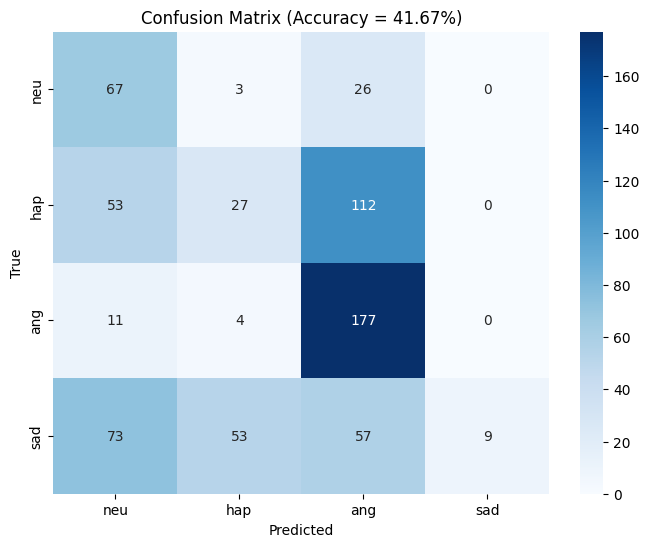

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model_emotions,
    yticklabels=model_emotions
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion Matrix (Accuracy = {accuracy*100:.2f}%)")
plt.show()

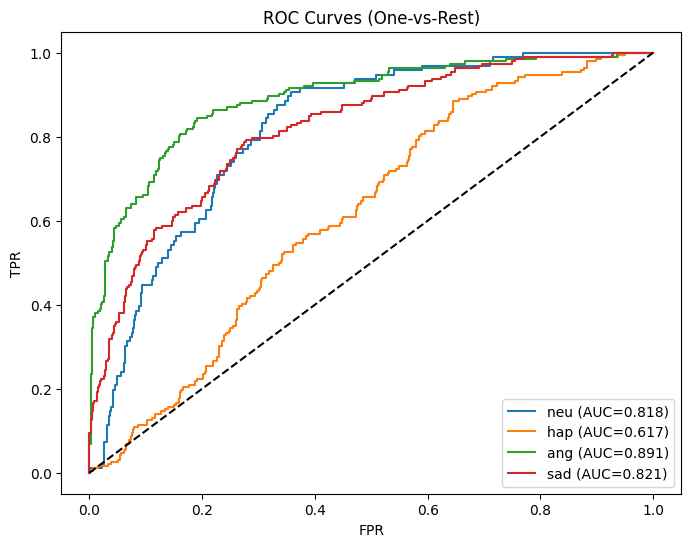

Mean AUC: 0.7867395471643518


In [ ]:
plt.figure(figsize=(8,6))

y_true_bin = label_binarize(y_true, classes=range(num_classes))
roc_aucs = []

for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    roc_aucs.append(roc_auc)

    plt.plot(fpr, tpr, label=f"{model_emotions[i]} (AUC={roc_auc:.3f})")

plt.plot([0,1], [0,1], 'k--')
plt.legend()
plt.title("ROC Curves (One-vs-Rest)")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.show()

print("Mean AUC:", np.mean(roc_aucs))